# Evaluating Pyrite in SAV across the Chesapeake Bay Salinity Gradient



## Load the data 

In [2]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from scipy.stats import spearmanr
import cartopy as cp
import cartopy.crs as ccrs
import matplotlib.ticker as mticker 
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature
from scipy.stats import kruskal
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from scipy import stats

# Read the csv file into a table (DataFrame) called T
T = pd.read_csv('Raw_data2.csv')

# Give the columns short names
T.columns = ['sample', 'depth', 'pyrite', 'd50', 'location', 'coreType', 'salinity']

# The six sites, ordered from fresh water to salty water
sites = ['susquehanna_flats', 'severn_river', 'goodwin_island',
         'gwynn_island', 'crisfield', 'south_bay']

# Same names but without underscores and capitilize the first letter
site_labels = [s.replace('_', ' ').title() for s in sites]

# Adressing one color per site (light blue = fresh - dark blue = salty)
colors = np.array([[0.65, 0.84, 0.96],
                   [0.45, 0.71, 0.90],
                   [0.28, 0.56, 0.82],
                   [0.16, 0.42, 0.70],
                   [0.08, 0.28, 0.52],
                   [0.02, 0.15, 0.35]])

#labels for the axes with units
pyrite_label = 'Pyrite (mg S/g dry sed.)'
d50_label    = r'Grain size $D_{50}$ ($\mu$m)'
depth_label  = 'Depth (cm)'

# True/False lists: is each row a short core? a vibracore?
is_short = T['coreType'] == 'short_core'
is_vibra = T['coreType'] == 'vibracore'

T.head()

,sample,depth,pyrite,d50,location,coreType,salinity
0,SQF-12-1-1,1.0,0.509427,361.0,susquehanna_flats,short_core,0
1,SQF-12-1-2,3.0,0.825505,285.0,susquehanna_flats,short_core,0
2,SQF-12-1-3,5.0,1.796983,347.5,susquehanna_flats,short_core,0
3,SQF-12-1-6,11.0,2.163411,259.0,susquehanna_flats,short_core,0
4,SQF-12-1-9,17.0,1.749952,365.0,susquehanna_flats,short_core,0


## Overview of all sites plots

### Pyrite at each site showing salinity values

In [33]:
# Summary table: one row per site
rows = []
for i in range(6):
    r = T['location'] == sites[i]
    p = T.loc[r, 'pyrite'].dropna()
    g = T.loc[r, 'd50'].dropna()
    rows.append({'Site': site_labels[i],
                 'Salinity': T.loc[r, 'salinity'].median(),
                 'n': len(p),
                 'Pyrite mean': p.mean(), 'Pyrite median': p.median(),
                 'Pyrite SD': p.std(), 'Pyrite max': p.max(),
                 'D50 median (um)': g.median()})
summary = pd.DataFrame(rows).round(2)
print(summary.to_string(index=False))

# Do the sites differ in pyrite? (Kruskal-Wallis = non-parametric ANOVA)
groups = [T.loc[T['location'] == s, 'pyrite'].dropna() for s in sites]
H, p_kw = kruskal(*groups)
print(f'\nKruskal-Wallis across sites: H = {H:.2f}, p = {p_kw:.2e}')

             Site  Salinity  n  Pyrite mean  Pyrite median  Pyrite SD  Pyrite max  D50 median (um)
Susquehanna Flats       0.0 52         1.64           1.37       1.09        5.71           241.50
     Severn River       8.0 39         2.21           1.97       1.04        5.64           221.50
   Goodwin Island      20.0 80         5.37           4.15       4.25       17.87           115.00
     Gwynn Island      20.0 10         2.23           1.85       1.31        4.92           201.00
        Crisfield      30.0 23         9.04           8.08       5.90       18.96            89.55
        South Bay      33.0 54         7.87           6.91       3.64       20.00            78.20

Kruskal-Wallis across sites: H = 118.79, p = 5.67e-24


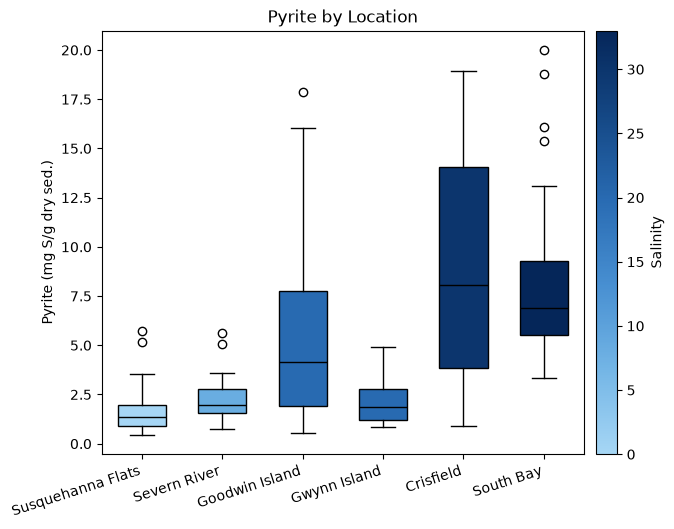

In [2]:
# Turn custom RGB array into a continuous colormap
salinity_cmap = mcolors.LinearSegmentedColormap.from_list('chesapeake_blues', colors)

# Get the salinity for each site in order
site_salinities = [T.loc[T['location'] == site, 'salinity'].median() for site in sites]

# Map the colormap on the salinity range
norm = mcolors.Normalize(vmin=T['salinity'].min(), vmax=T['salinity'].max())

fig, ax = plt.subplots(figsize=(7.5, 5.5))

for i in range(6):
  rows = T['location'] == sites[i]
  values = T.loc[rows, 'pyrite'].dropna()
  bp = ax.boxplot(values,positions=[i + 1],widths=0.6,patch_artist=True,medianprops=dict(color='black'),)

# Color each box based on salinity
  bp['boxes'][0].set_facecolor(salinity_cmap(norm(site_salinities[i])))

# Add colorbar 
sm = cm.ScalarMappable(cmap=salinity_cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Salinity')

ax.set_xticks(range(1, 7))
ax.set_xticklabels(site_labels, rotation=18, ha='right')
ax.set_ylabel(pyrite_label)
ax.set_title('Pyrite by Location')
ax.grid(False)
plt.show()

### Pyrite vs salinity

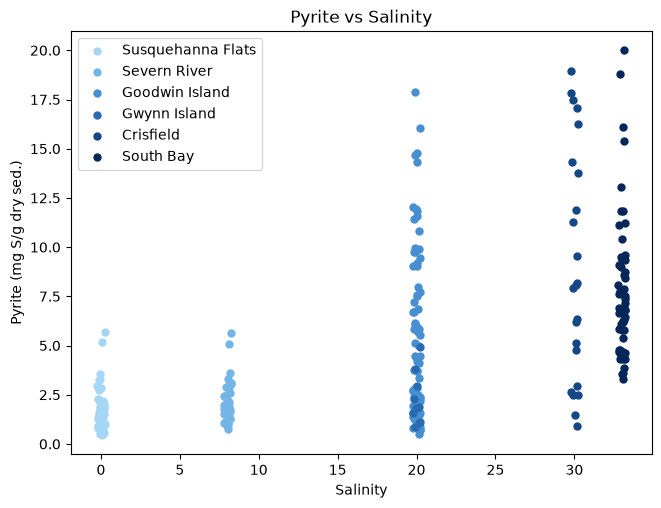

In [3]:
#scatter plot of pyrite vs salinity using the same colorcode 
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for i in range(6):
    rows = T['location'] == sites[i]
    # add a tiny random shift to salinity so points don't sit on top of each other (called jittering)
    x = T.loc[rows, 'salinity'] + 0.5 * (np.random.rand(rows.sum()) - 0.5)
    ax.scatter(x, T.loc[rows, 'pyrite'], s=25, color=colors[i], label=site_labels[i])

ax.set_xlabel('Salinity')
ax.set_ylabel(pyrite_label)
ax.set_title('Pyrite vs Salinity')
ax.legend(loc='upper left')
ax.grid(False)
plt.show()

### Pyrite vs grain size

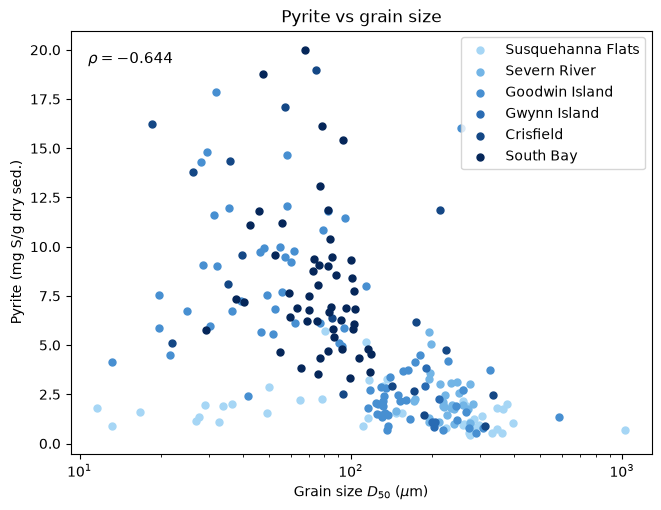

In [4]:
#scatter plot of pyrite vs grain size using a log scale
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for i in range(6):
    rows = T['location'] == sites[i]
    ax.scatter(T.loc[rows, 'd50'], T.loc[rows, 'pyrite'], s=25, color=colors[i], label=site_labels[i])

# Calculate Spearman correlation
valid = T['location'].isin(sites[:6]) & T['d50'].notna() & T['pyrite'].notna()
rho, p_val = spearmanr(T.loc[valid, 'd50'], T.loc[valid, 'pyrite'])

# Add Spearman text 
ax.text(0.03, 0.95, f'$\\rho = {rho:.3f}$',transform=ax.transAxes,fontsize=11,
    verticalalignment='top',bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='none'))

ax.set_xscale('log')                                  # log scale: grain sizes vary
ax.set_xlabel(d50_label)
ax.set_ylabel(pyrite_label)
ax.set_title('Pyrite vs grain size')
ax.legend(loc='upper right')
ax.grid(False)
plt.show()

### Short cores: pyrite vs depth

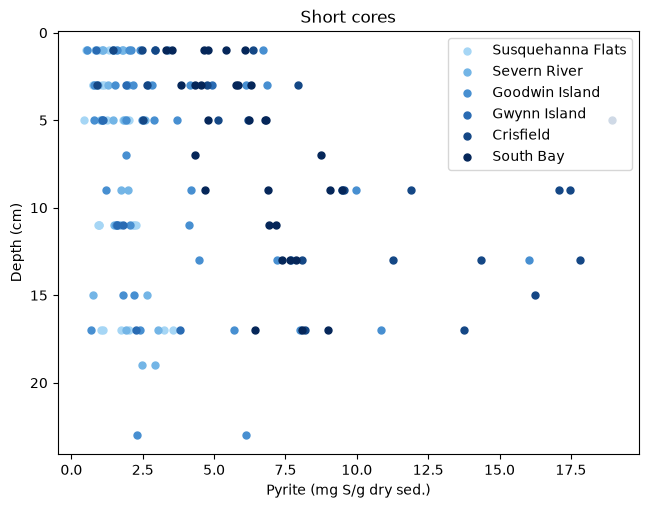

In [5]:
# Scatter plot to visualize pyrite accumulation in the short push cores
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for i in range(6):
    rows = (T['location'] == sites[i]) & is_short
    ax.scatter(T.loc[rows, 'pyrite'], T.loc[rows, 'depth'], s=25, color=colors[i], label=site_labels[i])

ax.invert_yaxis()                                     # depth 0 at the top
ax.set_xlabel(pyrite_label)
ax.set_ylabel(depth_label)
ax.set_title('Short cores')
ax.legend(loc='best')
ax.grid(False)
plt.show()

### Vibracores: pyrite vs depth

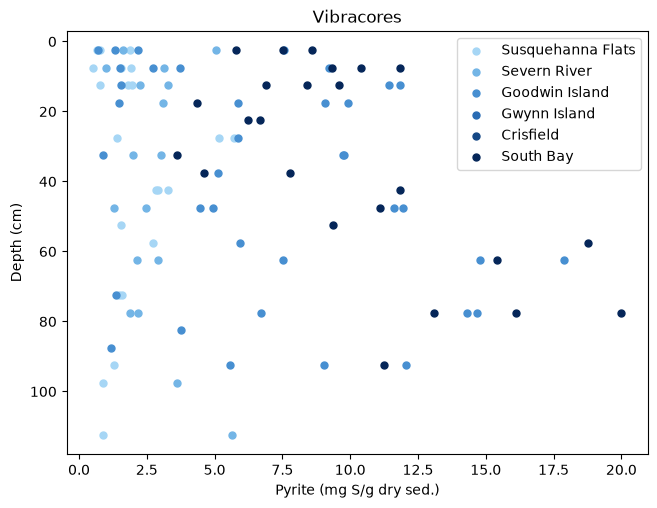

In [6]:
#same plot as above, but now representing vibracore data , which gather much longer core depths.
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for i in range(6):
    rows = (T['location'] == sites[i]) & is_vibra
    ax.scatter(T.loc[rows, 'pyrite'], T.loc[rows, 'depth'], s=25, color=colors[i], label=site_labels[i])

ax.invert_yaxis()
ax.set_xlabel(pyrite_label)
ax.set_ylabel(depth_label)
ax.set_title('Vibracores')
ax.legend(loc='best')
ax.grid(False)
plt.show()

### Grain size at each site

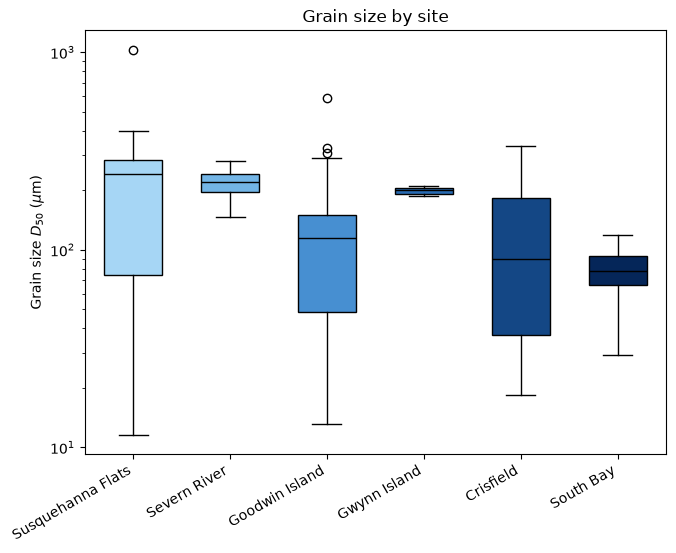

In [7]:
#this is a box and whisker plot representing grain size per site, 
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for i in range(6):
    rows = T['location'] == sites[i]
    values = T.loc[rows, 'd50'].dropna()              # skip missing grain sizes
    bp = ax.boxplot(values, positions=[i + 1], widths=0.6, patch_artist=True,
                    medianprops=dict(color='black'))
    bp['boxes'][0].set_facecolor(colors[i])

ax.set_xticks(range(1, 7))
ax.set_xticklabels(site_labels, rotation=30, ha='right')
ax.set_yscale('log')
ax.set_ylabel(d50_label)
ax.set_title('Grain size by site')
ax.grid(False)
plt.show()

## 3. Average pyrite vs depth for each site

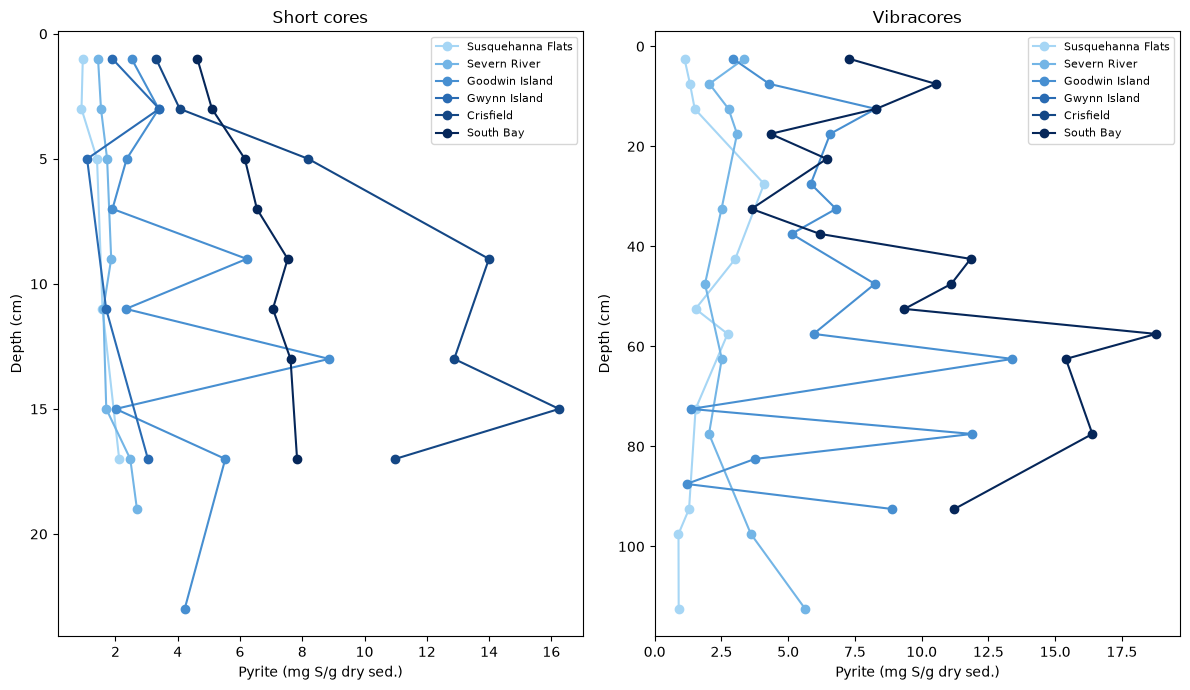

In [8]:
# plotting a line graph to look side by side the short core and vibracore pyrite data
fig, axes = plt.subplots(1, 2, figsize=(12, 7))

# Doing the same thing twice: first for short cores, then for vibracores
core_types  = ['short_core', 'vibracore']
plot_titles = ['Short cores', 'Vibracores']

for k in range(2):
    ax = axes[k]

    for i in range(6):
        # rows for this site AND this core type
        rows = (T['location'] == sites[i]) & (T['coreType'] == core_types[k])

        # average pyrite at each depth that was sampled (sorted by depth)
        avg = T[rows].groupby('depth')['pyrite'].mean()

        ax.plot(avg.values, avg.index, '-o', color=colors[i], markerfacecolor=colors[i],
                linewidth=1.5, label=site_labels[i])

    # Indented inside the k loop so both plots get formatted correctly
    ax.invert_yaxis()
    ax.set_xlabel(pyrite_label)
    ax.set_ylabel(depth_label)
    ax.set_title(plot_titles[k])
    ax.legend(loc='best', fontsize=8)
    ax.grid(False)

plt.tight_layout()
plt.show()

## 4. Pyrite vs grain size, one panel per site

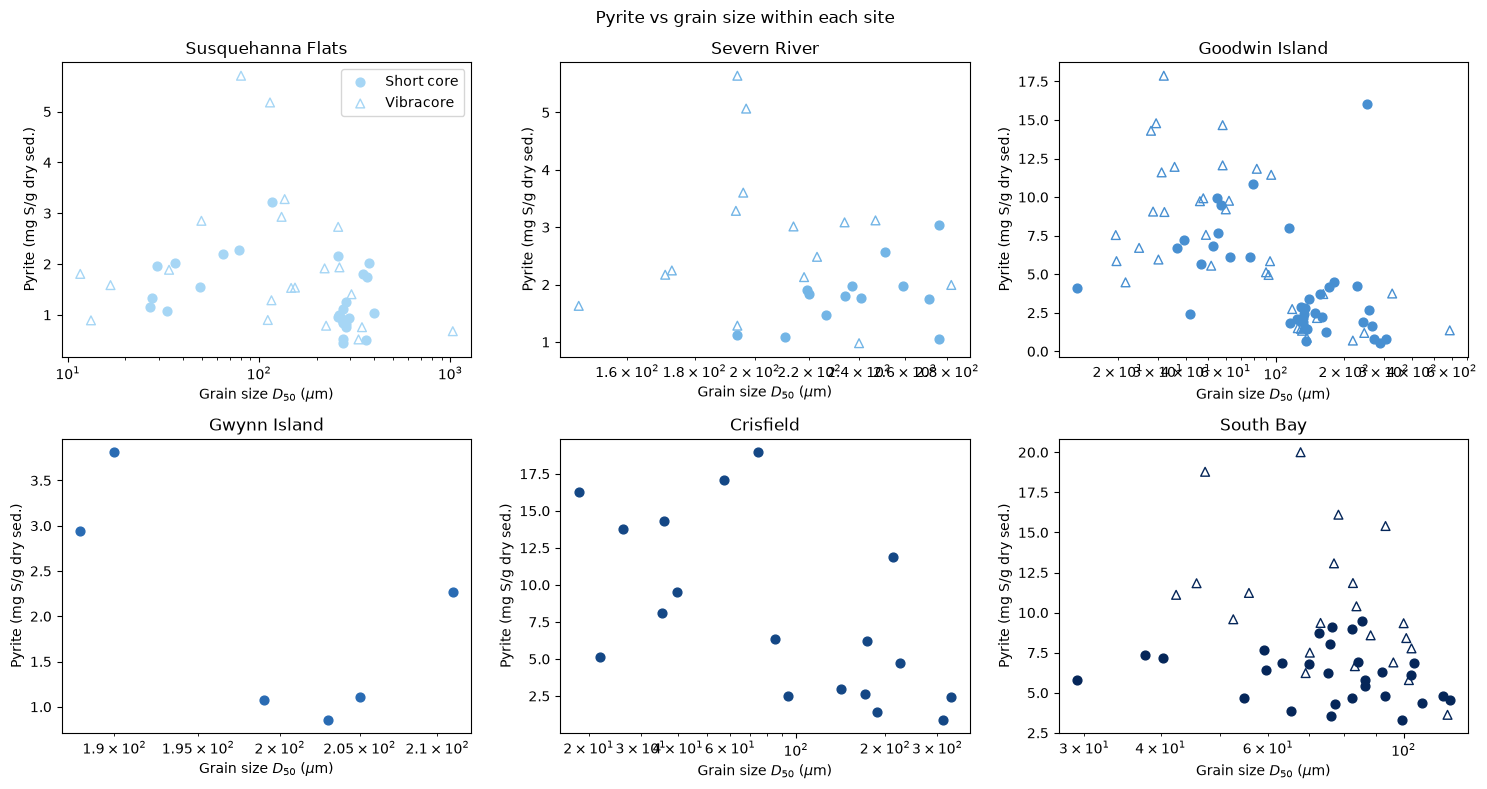

In [9]:
#comparing grainsize vs pyrite values per site
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i in range(6):
    ax = axes[i]

    short_rows = (T['location'] == sites[i]) & is_short
    vibra_rows = (T['location'] == sites[i]) & is_vibra

    # short cores = filled circles
    ax.scatter(T.loc[short_rows, 'd50'], T.loc[short_rows, 'pyrite'], s=40,
               color=colors[i], label='Short core')

    # vibracores = open triangles (only if this site has any)
    if vibra_rows.sum() > 0:
        ax.scatter(T.loc[vibra_rows, 'd50'], T.loc[vibra_rows, 'pyrite'], s=40,
                   facecolors='none', edgecolors=colors[i], marker='^', label='Vibracore')

    ax.set_xscale('log')
    ax.set_xlabel(d50_label)
    ax.set_ylabel(pyrite_label)
    ax.set_title(site_labels[i])
    ax.grid(False)

    if i == 0:
        ax.legend(loc='best')

fig.suptitle('Pyrite vs grain size within each site')
plt.tight_layout()
plt.show()

## Overlaid individual pyrite profiles across all sites

Six panels, one per location.

**Step 1:** work out which core / replicate each sample belongs to by reading its sample name.

In [10]:
# Create grouping columns (empty to start with)
T['mainCore']  = ''
T['profileID'] = ''

for r in range(len(T)):

    # Clean sample name (remove spaces)
    s = re.sub(r'\s+', '', str(T.loc[r, 'sample']).strip())
    loc = T.loc[r, 'location']

    # SUSQUEHANNA FLATS
    if loc == 'susquehanna_flats':
        m = re.match(r'^SQF-?(\d+)-(\d+)-\d+$', s)
        if m:
            T.loc[r, 'mainCore']  = 'SQF' + m.group(1)
            T.loc[r, 'profileID'] = 'SQF' + m.group(1) + '-R' + m.group(2)
        else:
            m = re.match(r'^SQF(\d+)VB-\d+$', s)
            if m:
                T.loc[r, 'mainCore']  = 'SQF' + m.group(1)
                T.loc[r, 'profileID'] = 'SQF' + m.group(1) + '-VB'

    # SEVERN RIVER
    elif loc == 'severn_river':
        m = re.match(r'^SVR(\d+)-(\d+)-\d+$', s)
        if m:
            T.loc[r, 'mainCore']  = 'SVR' + m.group(1)
            T.loc[r, 'profileID'] = 'SVR' + m.group(1) + '-R' + m.group(2)
        else:
            m = re.match(r'^SVR(\d+)VB-\d+$', s)
            if m:
                T.loc[r, 'mainCore']  = 'SVR' + m.group(1)
                T.loc[r, 'profileID'] = 'SVR' + m.group(1) + '-VB'

    # GOODWIN ISLAND
    elif loc == 'goodwin_island':
        m = re.match(r'^6G(\d+)([AB])-\d+$', s)
        if m:
            T.loc[r, 'mainCore']  = '6G' + m.group(1)
            T.loc[r, 'profileID'] = '6G' + m.group(1) + m.group(2)
        else:
            m = re.match(r'^6G(\d+)VB-\d+$', s)
            if m:
                T.loc[r, 'mainCore']  = '6G' + m.group(1)
                T.loc[r, 'profileID'] = '6G' + m.group(1) + '-VB'

    # CRISFIELD
    elif loc == 'crisfield':
        m = re.match(r'^6CR(\d+)([AB])-\d+$', s)
        if m:
            T.loc[r, 'mainCore']  = '6CR' + m.group(1)
            T.loc[r, 'profileID'] = '6CR' + m.group(1) + m.group(2)

    # GWYNN ISLAND
    elif loc == 'gwynn_island':
        m = re.match(r'^7G(\d+)([AB])-\d+$', s)
        if m:
            T.loc[r, 'mainCore']  = '7G' + m.group(1)
            T.loc[r, 'profileID'] = '7G' + m.group(1) + m.group(2)

    # SOUTH BAY
    elif loc == 'south_bay':
        m = re.match(r'^S5([NCS])(\d+)-\d+$', s)
        if m:
            T.loc[r, 'mainCore']  = 'S5' + m.group(1)
            T.loc[r, 'profileID'] = 'S5' + m.group(1) + m.group(2)
        else:
            # These samples continue the S5N1 short core
            if re.match(r'^SB5N-\d+$', s):
                T.loc[r, 'mainCore']  = 'S5N'
                T.loc[r, 'profileID'] = 'S5N1'

            # North vibracore
            if re.match(r'^SBNVB-\d+$', s):
                T.loc[r, 'mainCore']  = 'S5N'
                T.loc[r, 'profileID'] = 'S5N-VB'

            # Central vibracore
            if re.match(r'^(S5CVB|SBCVB)-\d+$', s):
                T.loc[r, 'mainCore']  = 'S5C'
                T.loc[r, 'profileID'] = 'S5C-VB'

            # South vibracore
            if re.match(r'^SBSVB-\d+$', s):
                T.loc[r, 'mainCore']  = 'S5S'
                T.loc[r, 'profileID'] = 'S5S-VB'

**Step 2:** make the six location panels.

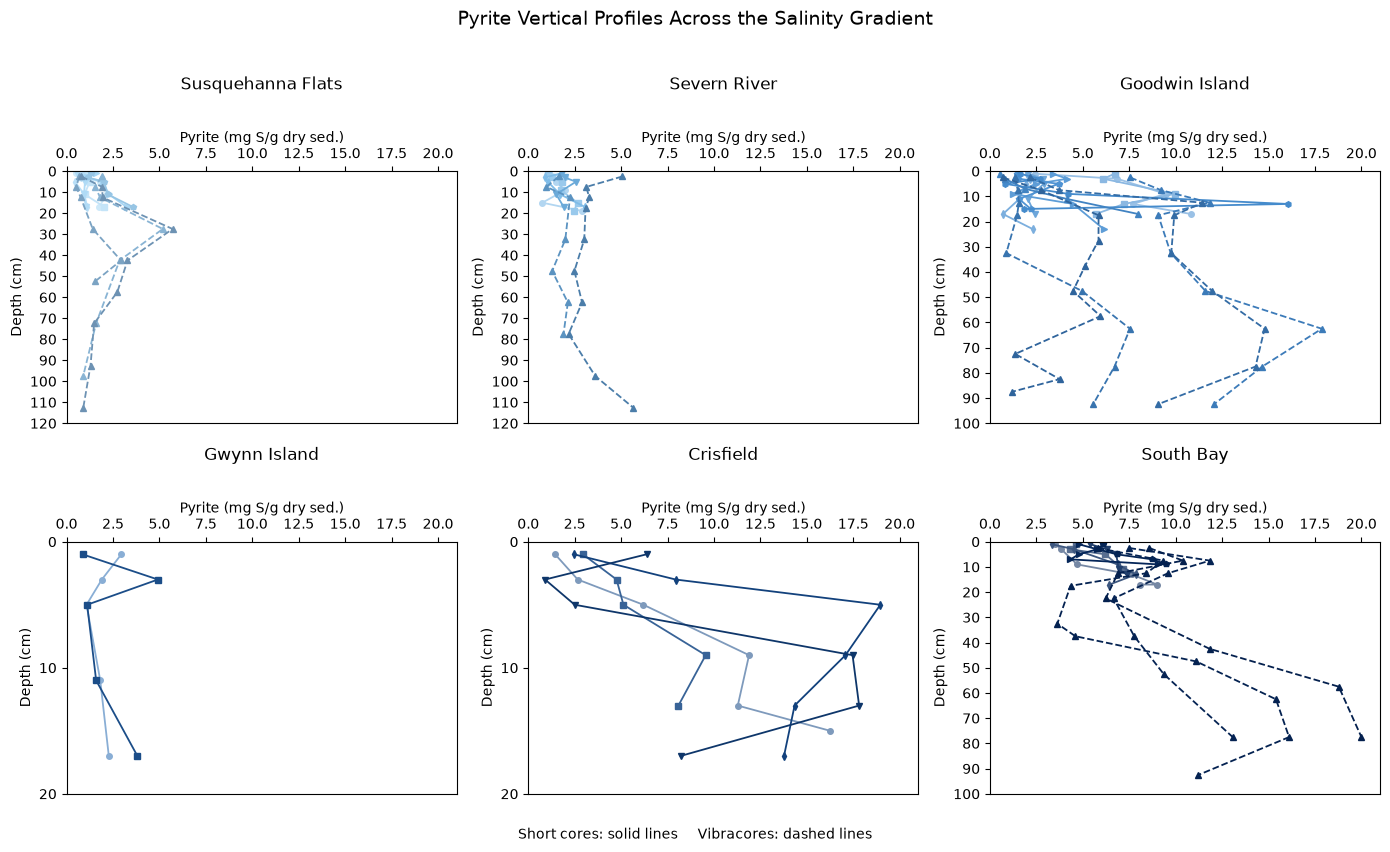

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
axes = axes.flatten()

# Use the same pyrite axis limits across all locations
max_pyrite = T['pyrite'].max()

# Different markers for individual profiles
markers = ['o', 's', 'd', 'v', '>', 'p', 'h', '^']

for i in range(6):
    ax = axes[i]

    # Find samples from this location
    site_rows = T['location'] == sites[i]

    # Find maximum depth for this individual location (rounded up to nearest 10)
    valid_depths = T.loc[site_rows, 'depth'].dropna()
    max_depth = int(np.ceil(valid_depths.max() / 10) * 10)

    # Find individual core profiles (keep the order they first appear)
    site_profiles = list(dict.fromkeys(T.loc[site_rows, 'profileID']))
    site_profiles = [p for p in site_profiles if p != '']
    n_profiles = len(site_profiles)

    # Plot each individual profile
    for j, prof in enumerate(site_profiles):

        # Samples belonging to this profile, with missing values removed, sorted by depth
        core = T[site_rows & (T['profileID'] == prof)]
        core = core.dropna(subset=['pyrite', 'depth']).sort_values('depth')

        # Create different shades of the location color
        shade_position = j / max(n_profiles - 1, 1)

        if shade_position <= 0.5:
            amount = 0.45 * (1 - shade_position / 0.5)
            core_color = colors[i] + amount * (1 - colors[i])        # lighter
        else:
            amount = 0.35 * ((shade_position - 0.5) / 0.5)
            dark_blue = np.array([0.01, 0.08, 0.22])
            core_color = colors[i] * (1 - amount) + dark_blue * amount   # darker

        # Short cores = solid line, vibracores = dashed line
        if (core['coreType'] == 'vibracore').any():
            line_style = '--'
            marker_style = '^'
        else:
            line_style = '-'
            marker_style = markers[j % len(markers)]

        # Plot individual core profile
        ax.plot(core['pyrite'], core['depth'],
                color=core_color, linestyle=line_style, marker=marker_style,
                markerfacecolor=core_color, markeredgecolor=core_color,
                linewidth=1.3, markersize=4)

    # Put pyrite values on top axis
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position('top')

    # Keep axis scales consistent. Depth increases downward (max depth first).
    ax.set_xlim(0, max_pyrite * 1.05)
    ax.set_ylim(max_depth, 0)
    ax.set_yticks(np.arange(0, max_depth + 1, 10))

    # Axis labels and title
    ax.set_xlabel(pyrite_label)
    ax.set_ylabel(depth_label)
    ax.set_title(site_labels[i], pad=30)

    ax.grid(False)
    ax.tick_params(labelsize=10)

# Overall figure title
fig.suptitle('Pyrite Vertical Profiles Across the Salinity Gradient', fontsize=14)

# Small explanation of line styles
fig.text(0.5, 0.005, 'Short cores: solid lines     Vibracores: dashed lines',
         ha='center', fontsize=10)

plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

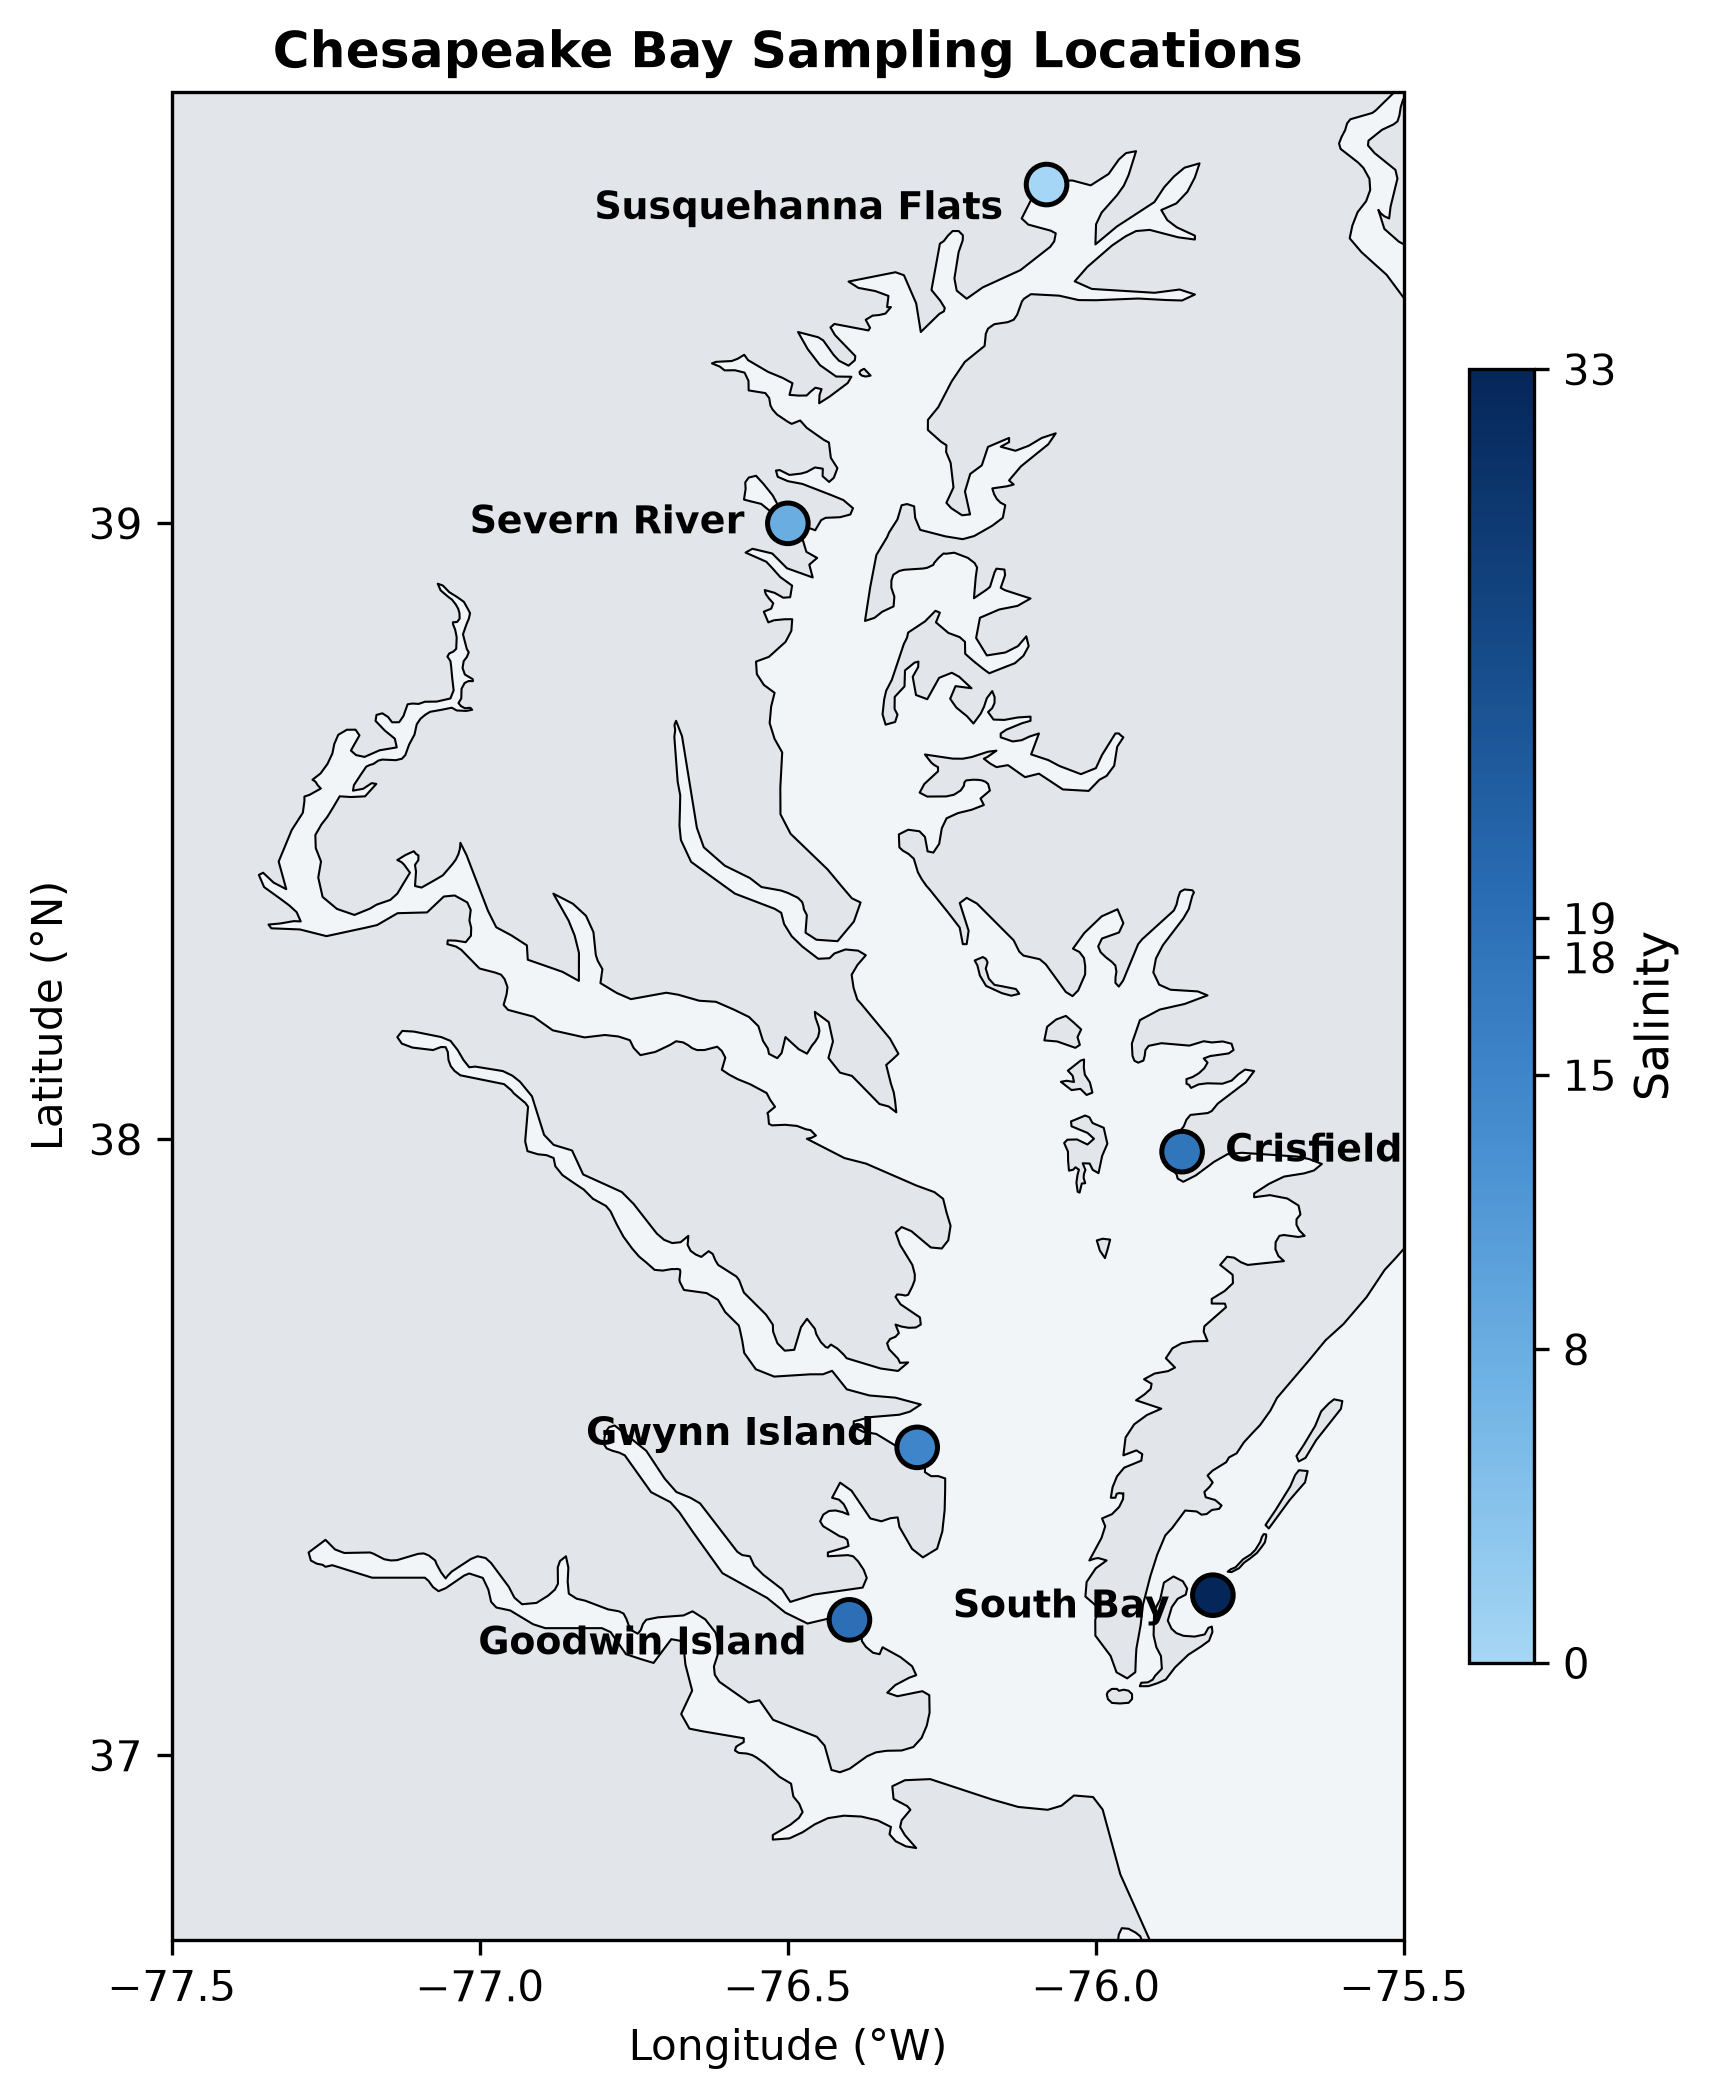

In [29]:
# 1. Your 6 sampling sites (ordered fresh -> salty)
sites = [
    {"name": "Susquehanna Flats", "lon": -76.08, "lat": 39.55, "salinity": 0},
    {"name": "Severn River",      "lon": -76.50, "lat": 39.00, "salinity": 8},
    {"name": "Gwynn Island",      "lon": -76.29, "lat": 37.50, "salinity": 15},
    {"name": "Crisfield",         "lon": -75.86, "lat": 37.98, "salinity": 18},
    {"name": "Goodwin Island",    "lon": -76.40, "lat": 37.22, "salinity": 19},
    {"name": "South Bay",         "lon": -75.81, "lat": 37.26, "salinity": 33},
]

lons = [s["lon"] for s in sites]
lats = [s["lat"] for s in sites]
sals = [s["salinity"] for s in sites]

# 2. Custom blue salinity colormap (exact match to your MATLAB blueAnchors)
blue_anchors = [
    [0.65, 0.84, 0.96],  # Light blue (fresh)
    [0.45, 0.71, 0.90],
    [0.28, 0.56, 0.82],
    [0.16, 0.42, 0.70],
    [0.08, 0.28, 0.52],
    [0.02, 0.15, 0.35],  # Dark blue (salty)
]
blue_cmap = mcolors.LinearSegmentedColormap.from_list("blue_salinity", blue_anchors, N=256)

# 3. Create map using PlateCarree
fig, ax = plt.subplots(figsize=(7, 8), dpi=300, subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_extent([-77.5, -75.5, 36.7, 39.7], crs=ccrs.PlateCarree())

# 4. Draw Chesapeake Bay land and water (neutral water tone so light-blue dots pop)
ax.set_facecolor('#F2F5F8')  # Pale neutral water
ax.add_feature(cfeature.LAND.with_scale('10m'), facecolor='#E2E5E9', edgecolor='black', linewidth=0.5)

# 5. Plot sampling dots colored by the blue salinity gradient
norm = mcolors.Normalize(vmin=0, vmax=33)
sc = ax.scatter(
    lons, lats, c=sals, cmap=blue_cmap, norm=norm,
    s=95, edgecolors='black', linewidths=1.2, zorder=5
)

# 6. Label each dot
offsets = {
    "Susquehanna Flats": (-0.07, -0.04, 'right'),
    "Severn River":      (-0.07,  0.00, 'right'),
    "Gwynn Island":      (-0.07,  0.02, 'right'),
    "Crisfield":         ( 0.07,  0.00, 'left'),
    "Goodwin Island":    (-0.07, -0.04, 'right'),
    "South Bay":         ( -0.07, -0.02, 'right'),
}

for s in sites:
    dx, dy, align = offsets[s["name"]]
    ax.text(s["lon"] + dx, s["lat"] + dy, s["name"],
            fontsize=9, fontweight='bold', ha=align, va='center', zorder=6)

# 7. Add colorbar and lat/lon ticks
cbar = plt.colorbar(sc, ax=ax, shrink=0.7, pad=0.04)
cbar.set_label('Salinity', fontsize=11)
cbar.set_ticks([0, 8, 15, 18, 19, 33])

ax.set_xticks([-77.5, -77.0, -76.5, -76.0, -75.5], crs=ccrs.PlateCarree())
ax.set_yticks([37.0, 38.0, 39.0], crs=ccrs.PlateCarree())
ax.set_xlabel('Longitude (°W)')
ax.set_ylabel('Latitude (°N)')
ax.set_title('Chesapeake Bay Sampling Locations', fontweight='bold')

plt.savefig('chesapeake_map.png', dpi=300, bbox_inches='tight')
plt.show()

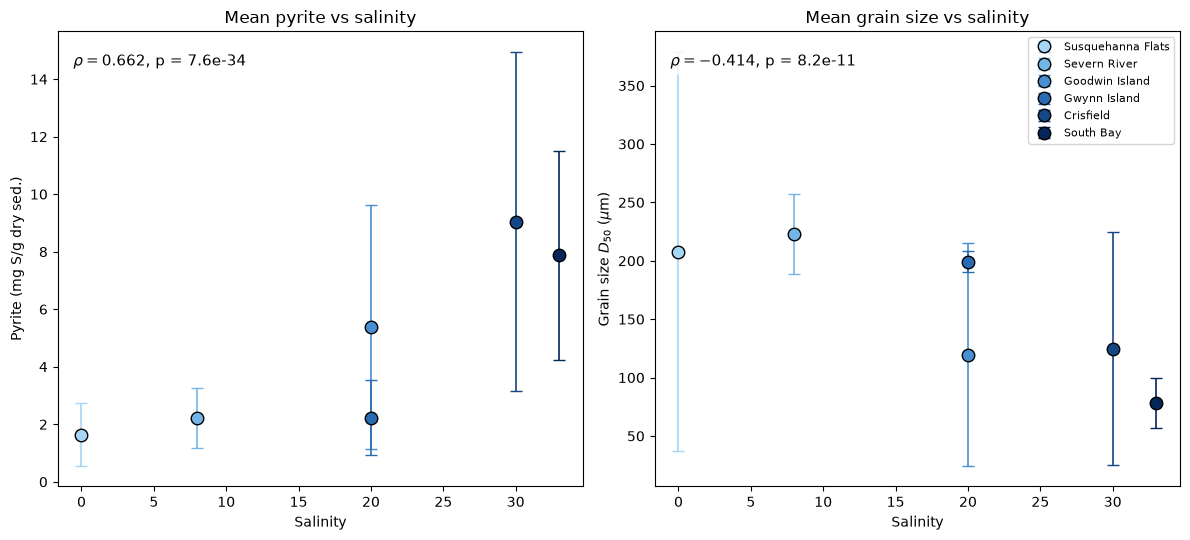

In [37]:
# Site means (+/- 1 SD) of pyrite and grain size against salinity
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

for k, (col, lab) in enumerate([('pyrite', pyrite_label), ('d50', d50_label)]):
    ax = axes[k]
    for i in range(6):
        rows = T['location'] == sites[i]
        vals = T.loc[rows, col].dropna()
        sal = T.loc[rows, 'salinity'].median()
        ax.errorbar(sal, vals.mean(), yerr=vals.std(), fmt='o', color=colors[i],
                    markeredgecolor='black', markersize=9, capsize=4,
                    elinewidth=1.2, label=site_labels[i])

    # Spearman correlation using every sample, not just the site means
    valid = T['location'].isin(sites) & T[col].notna()
    rho, p_val = spearmanr(T.loc[valid, 'salinity'], T.loc[valid, col])
    ax.text(0.03, 0.95, f'$\\rho = {rho:.3f}$, p = {p_val:.1e}', transform=ax.transAxes,
            fontsize=11, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='none'))

    ax.set_xlabel('Salinity')
    ax.set_ylabel(lab)
    ax.grid(False)

axes[0].set_title('Mean pyrite vs salinity')
axes[1].set_title('Mean grain size vs salinity')
axes[1].legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

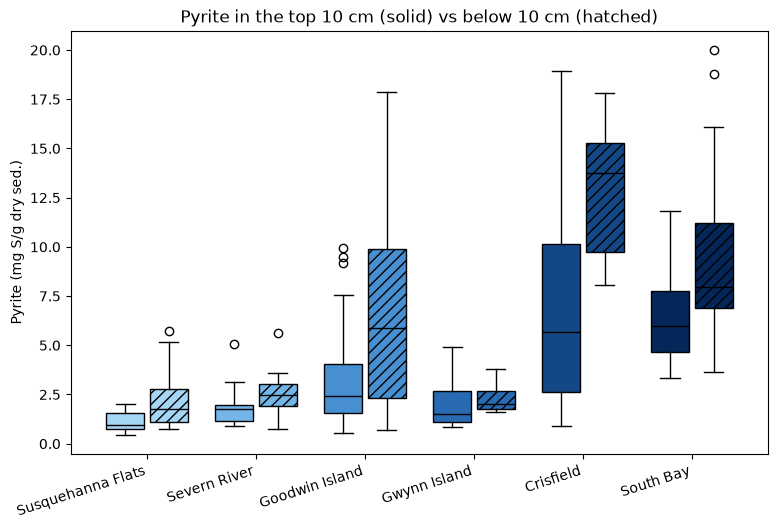

In [38]:
# Is there more pyrite below the surface? Compare top 10 cm with everything deeper
fig, ax = plt.subplots(figsize=(9, 5.5))

for i in range(6):
    rows = T['location'] == sites[i]
    shallow = T.loc[rows & (T['depth'] <= 10), 'pyrite'].dropna()
    deep    = T.loc[rows & (T['depth'] > 10),  'pyrite'].dropna()

    # shallow = solid, deep = hatched
    bp1 = ax.boxplot(shallow, positions=[i + 0.8], widths=0.35, patch_artist=True,
                     medianprops=dict(color='black'))
    bp2 = ax.boxplot(deep, positions=[i + 1.2], widths=0.35, patch_artist=True,
                     medianprops=dict(color='black'))
    bp1['boxes'][0].set_facecolor(colors[i])
    bp2['boxes'][0].set_facecolor(colors[i])
    bp2['boxes'][0].set_hatch('///')

ax.set_xticks(range(1, 7))
ax.set_xticklabels(site_labels, rotation=18, ha='right')
ax.set_ylabel(pyrite_label)
ax.set_title('Pyrite in the top 10 cm (solid) vs below 10 cm (hatched)')
ax.grid(False)
plt.show()

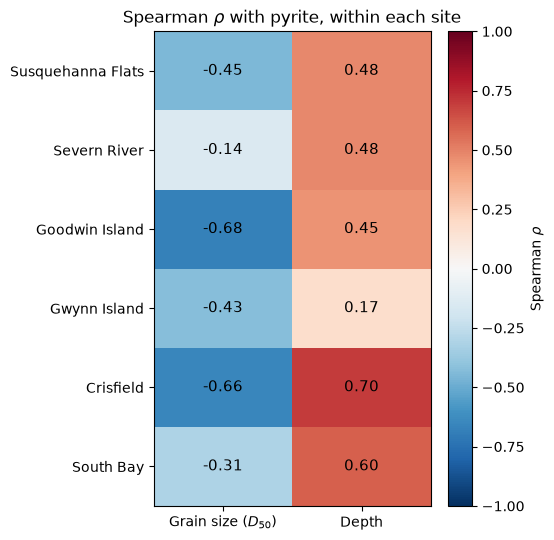

In [39]:
# Spearman correlation of pyrite with grain size and with depth, within each site
corr = np.full((6, 2), np.nan)
for i in range(6):
    rows = T['location'] == sites[i]
    for j, col in enumerate(['d50', 'depth']):
        valid = rows & T[col].notna() & T['pyrite'].notna()
        if valid.sum() > 3:                             # need a few points for a correlation
            corr[i, j], _ = spearmanr(T.loc[valid, col], T.loc[valid, 'pyrite'])

fig, ax = plt.subplots(figsize=(5.5, 5.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')

# Write the value inside each cell
for i in range(6):
    for j in range(2):
        if not np.isnan(corr[i, j]):
            ax.text(j, i, f'{corr[i, j]:.2f}', ha='center', va='center', fontsize=11)

ax.set_xticks([0, 1])
ax.set_xticklabels(['Grain size ($D_{50}$)', 'Depth'])
ax.set_yticks(range(6))
ax.set_yticklabels(site_labels)
ax.set_title('Spearman $\\rho$ with pyrite, within each site')
fig.colorbar(im, ax=ax, label=r'Spearman $\rho$')
plt.tight_layout()
plt.show()

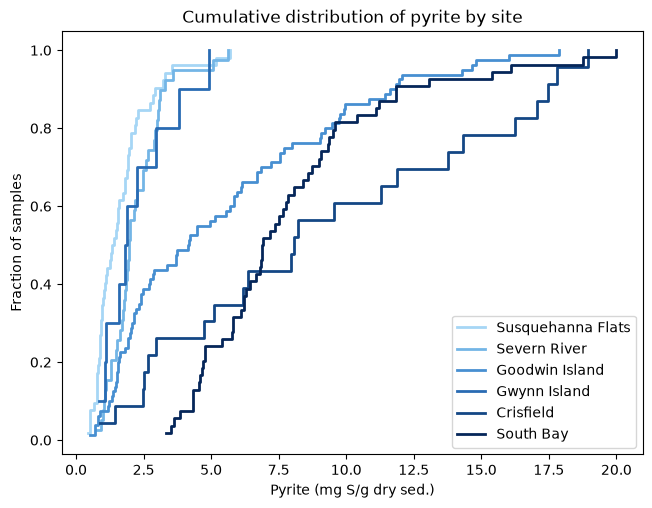

In [40]:
# Cumulative distribution of pyrite at each site (shifted right = more pyrite overall)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for i in range(6):
    rows = T['location'] == sites[i]
    values = np.sort(T.loc[rows, 'pyrite'].dropna().values)
    cumulative = np.arange(1, len(values) + 1) / len(values)
    ax.step(values, cumulative, where='post', color=colors[i], linewidth=2, label=site_labels[i])

ax.set_xlabel(pyrite_label)
ax.set_ylabel('Fraction of samples')
ax.set_title('Cumulative distribution of pyrite by site')
ax.legend(loc='lower right')
ax.grid(False)
plt.show()

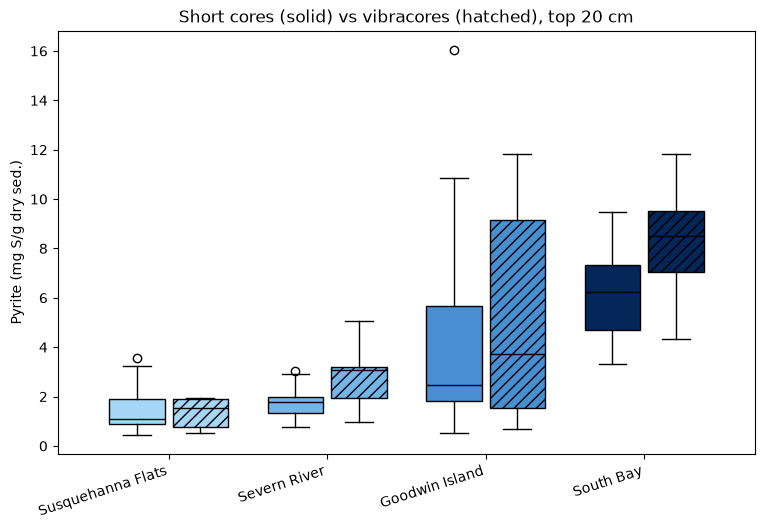

In [41]:
# Do short cores and vibracores agree where they overlap? (top 20 cm only)
fig, ax = plt.subplots(figsize=(9, 5.5))

vibra_sites = [i for i in range(6) if (T['location'].eq(sites[i]) & is_vibra).any()]

for n, i in enumerate(vibra_sites):
    rows = (T['location'] == sites[i]) & (T['depth'] <= 20)
    short = T.loc[rows & is_short, 'pyrite'].dropna()
    vibra = T.loc[rows & is_vibra, 'pyrite'].dropna()

    # short core = solid box, vibracore = hatched box
    bp1 = ax.boxplot(short, positions=[n + 0.8], widths=0.35, patch_artist=True,
                     medianprops=dict(color='black'))
    bp2 = ax.boxplot(vibra, positions=[n + 1.2], widths=0.35, patch_artist=True,
                     medianprops=dict(color='black'))
    bp1['boxes'][0].set_facecolor(colors[i])
    bp2['boxes'][0].set_facecolor(colors[i])
    bp2['boxes'][0].set_hatch('///')

ax.set_xticks(range(1, len(vibra_sites) + 1))
ax.set_xticklabels([site_labels[i] for i in vibra_sites], rotation=18, ha='right')
ax.set_ylabel(pyrite_label)
ax.set_title('Short cores (solid) vs vibracores (hatched), top 20 cm')
ax.grid(False)
plt.show()

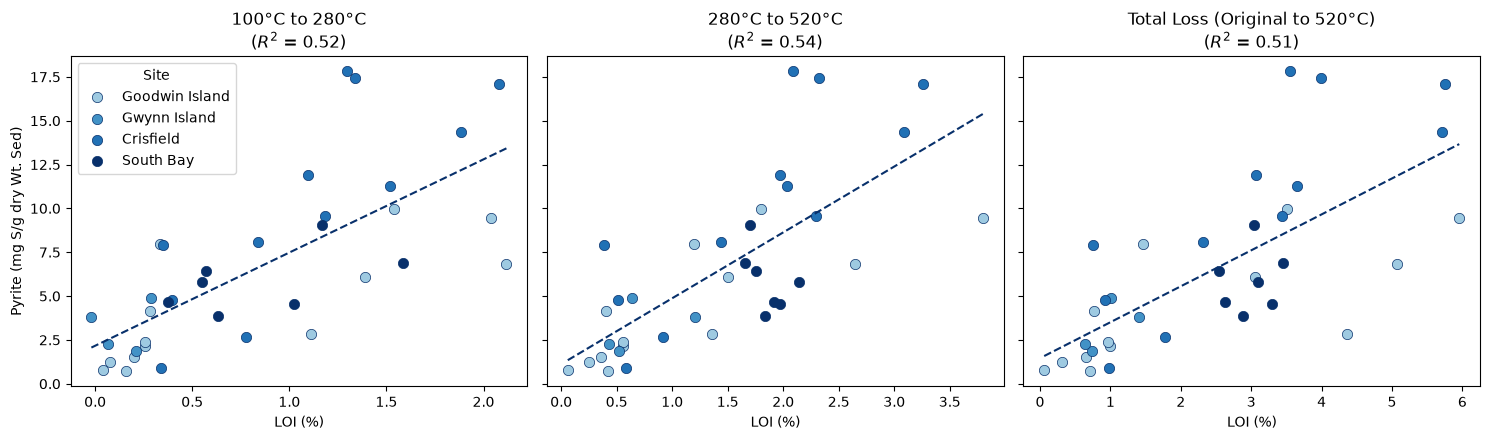

In [5]:
# load and merge data
loi = pd.read_csv('LOI_DATA(LOI_data).csv')
raw = pd.read_csv('Raw_data2.csv')
df = pd.merge(loi, raw, left_on='Sample', right_on='sample')

# define columns and blue shades for each site
cols = ['%difference100to280', '%difference280to520', '%totallossoriginalto520']
titles = ['100°C to 280°C', '280°C to 520°C', 'Total Loss (Original to 520°C)']

site_colors = {
    'goodwin_island': '#9ecae1',  # Light blue
    'gwynn_island':   '#4292c6',  # Medium blue
    'crisfield':      '#2171b5',  # Deep blue
    'south_bay':      '#08306b'   # Dark navy blue}

site_labels = {
    'goodwin_island': 'Goodwin Island',
    'gwynn_island':   'Gwynn Island',
    'crisfield':      'Crisfield',
    'south_bay':      'South Bay'}

#Create 3 simple side-by-side scatter plots
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, col, title in zip(axes, cols, titles):
    x_all = df[col]
    y_all = df['pyrite(mg S/g dry Wt. Sed)']
    
    # Plot each site in its own shade of blue
    for site, color in site_colors.items():
        sub = df[df['location'] == site]
        ax.scatter(sub[col], sub['pyrite(mg S/g dry Wt. Sed)'],
            color=color, label=site_labels[site],
            edgecolors='#08306b', linewidth=0.5, s=55)
    
    # Overall linear trendline
    m, b = np.polyfit(x_all, y_all, 1)
    x_line = np.linspace(x_all.min(), x_all.max(), 100)
    ax.plot(x_line, m * x_line + b, color='#08306b', linestyle='--')
    
    # R2 value
    r2 = np.corrcoef(x_all, y_all)[0, 1] ** 2
    ax.set_title(f"{title}\n($R^2$ = {r2:.2f})")
    ax.set_xlabel("LOI (%)")

axes[0].set_ylabel("Pyrite (mg S/g dry Wt. Sed)")
axes[0].legend(title="Site", frameon=True)

plt.tight_layout()
plt.savefig('simple_pyrite_loi_by_site.png', dpi=300)
plt.show()

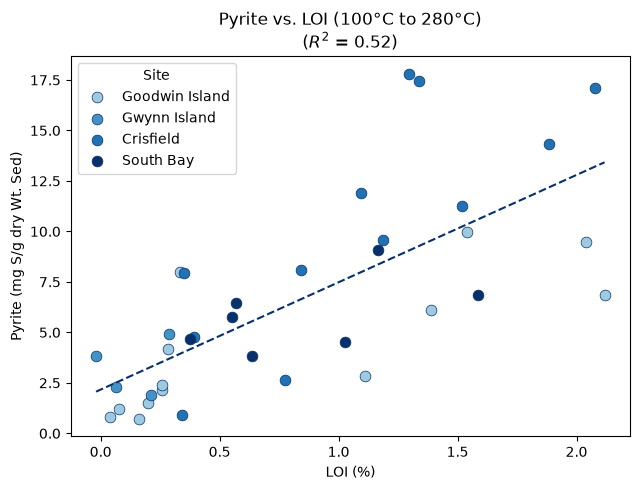

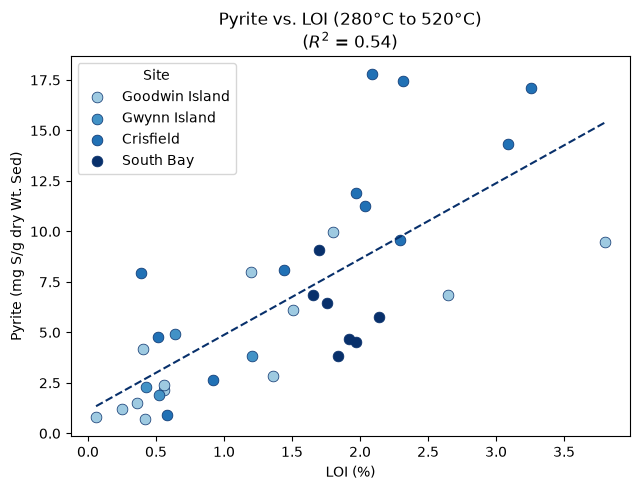

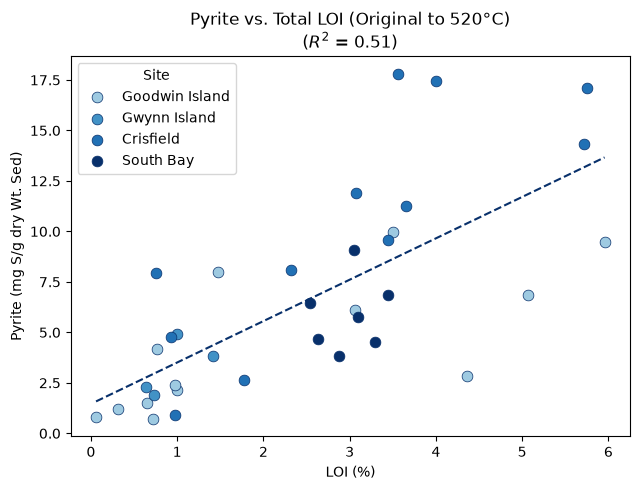

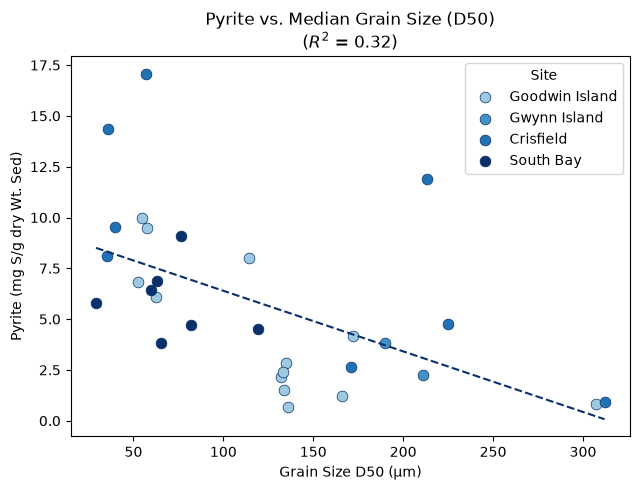

In [8]:
#Helper functions 
def make_single_plot(data, x_col, x_label, title, filename):
    fig, ax = plt.subplots(figsize=(6.5, 5))
    
    # Drop missing values for the specific x/y pair (needed for grain size)
    valid = data[[x_col, 'pyrite(mg S/g dry Wt. Sed)', 'location']].dropna()
    
    for site, color in site_colors.items():
        sub = valid[valid['location'] == site]
        ax.scatter(sub[x_col], sub['pyrite(mg S/g dry Wt. Sed)'],
            color=color, label=site_labels[site],
            edgecolors='#08306b', linewidth=0.5, s=60)
    
    # Linear trendline
    x_all = valid[x_col]
    y_all = valid['pyrite(mg S/g dry Wt. Sed)']
    m, b = np.polyfit(x_all, y_all, 1)
    x_line = np.linspace(x_all.min(), x_all.max(), 100)
    ax.plot(x_line, m * x_line + b, color='#08306b', linestyle='--')
    
    # R2 value
    r2 = np.corrcoef(x_all, y_all)[0, 1] ** 2
    ax.set_title(f"{title}\n($R^2$ = {r2:.2f})")
    ax.set_xlabel(x_label)
    ax.set_ylabel("Pyrite (mg S/g dry Wt. Sed)")
    ax.legend(title="Site", frameon=True)
    
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()

# generate the 4 separate plots
plots_to_make = [
    ('%difference100to280',     'LOI (%)',             'Pyrite vs. LOI (100°C to 280°C)',          'plot1_loi_100_280.png'),
    ('%difference280to520',     'LOI (%)',             'Pyrite vs. LOI (280°C to 520°C)',          'plot2_loi_280_520.png'),
    ('%totallossoriginalto520', 'LOI (%)',             'Pyrite vs. Total LOI (Original to 520°C)', 'plot3_loi_total.png'),
    ('D_50(um)',                'Grain Size D50 (µm)', 'Pyrite vs. Median Grain Size (D50)',     'plot4_grain_size.png')]

for col, xlabel, title, fname in plots_to_make:
    make_single_plot(df, col, xlabel, title, fname)